# backtesting demo
Fit strategy #1 (factor long-short) on the training window, backtest the full period **with costs**, and compare in-sample to the hold-out.

In [1]:
import pandas as pd

from quantskills.backtest import CostModel
from quantskills.data import synthetic_prices
from quantskills.eval import plot_tear_sheet, tear_sheet
from quantskills.strategies import FactorLongShort, run_strategy
from quantskills.utils import holdout_date

prices = synthetic_prices(seed=0)
train_end = holdout_date(prices.index.get_level_values("date"), 0.3)
run = run_strategy(
    FactorLongShort(), prices, train_end, CostModel(commission_bps=5, slippage_bps=5)
)
print("fitted factor weights:", {k: round(v, 3) for k, v in run.strategy.factor_weights_.items()})

fitted factor weights: {'momentum': 0.62, 'reversal': 0.051, 'low_vol': -0.328}


In [2]:
pd.DataFrame({"in-sample": tear_sheet(run.in_sample), "hold-out": tear_sheet(run.out_of_sample)})

,in-sample,hold-out
ann_return,0.097509,-0.026418
ann_vol,0.066983,0.068161
sharpe,1.422753,-0.358799
sortino,2.106446,-0.509275
max_drawdown,-0.079642,-0.106428
calmar,1.224344,-0.248227
hit_rate,0.549206,0.502646
n_days,630.0,378.0
gross_sharpe,1.528362,-0.227016
ann_turnover,6.988598,8.976859


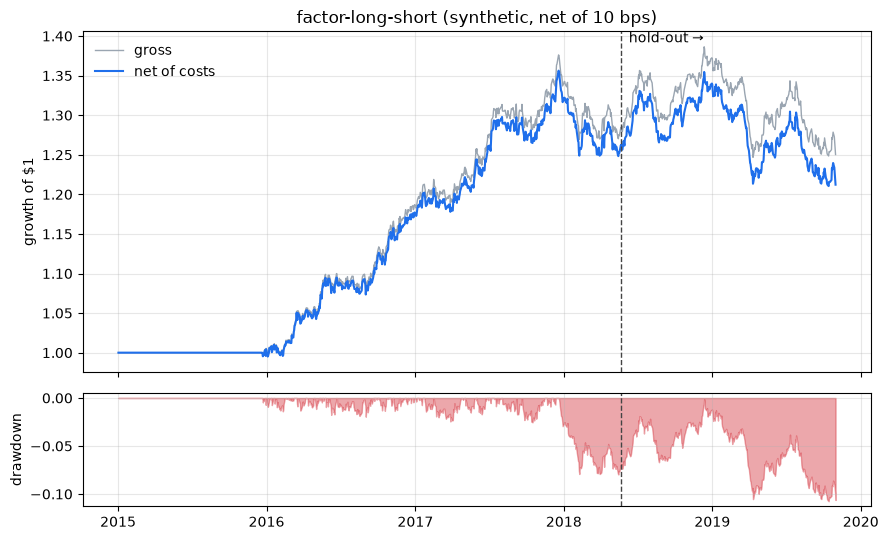

In [3]:
plot_tear_sheet(
    run.full, title="factor-long-short (synthetic, net of 10 bps)", split_date=train_end
);

Costs matter: the same strategy with 4x the trading costs.

In [4]:
expensive = run_strategy(FactorLongShort(), prices, train_end, CostModel(20, 20))
print(
    "IS Sharpe at 10 bps: {:.2f}, at 40 bps: {:.2f}".format(
        tear_sheet(run.in_sample)["sharpe"], tear_sheet(expensive.in_sample)["sharpe"]
    )
)

IS Sharpe at 10 bps: 1.42, at 40 bps: 1.10
